In [ ]:

import os, cv2, numpy as np, matplotlib.pyplot as plt
plt.rcParams['figure.dpi']=110

**¿Para qué sirve?**

Se utiliza para mostrar imágenes, normalizar inputs y también para guardar resultados, ejecutando esta sección una vez y reutilizando las otras celdas. Muestra una lista de imágenes con una fila de títulos.

Convierte una imagen almacenada como arreglo NumPy a formato float32, ajustando sus valores al rango de 0 a 1 y transformándola a escala de grises cuando contiene tres canales de color.

**Carga de imágenes**

Carga dos imágenes desde el almacenamiento local para utilizarlas en el ejercicio. Si los archivos no se encuentran en la ruta indicada, muestra un mensaje de aviso. Las rutas de las imágenes (`img_path1` e `img_path2`) se pueden modificar según la ubicación de los archivos.

In [2]:

def show(imgs, titles=None, cmap='gray', figsize=(12,4), suptitle=None):
    n=len(imgs); fig,axes=plt.subplots(1,n,figsize=figsize);
    if n==1: axes=[axes]
    if suptitle: fig.suptitle(suptitle)
    for ax,im,t in zip(axes,imgs,(titles or [""]*n)):
        ax.imshow(im, cmap=cmap); ax.set_title(t); ax.axis('off')
    plt.show()

In [11]:
import numpy as np
import cv2

def to_float01(img):
    img=np.asarray(img).astype(np.float32)
    if img.max()>1.0: img/=255.0
    if img.ndim==3: img=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    return img

In [4]:

def save(path,img): cv2.imwrite(path, np.clip((img*255).astype(np.uint8),0,255))

In [5]:

img_path1='radiografia.jpg'; img_path2='corte.jpg'


In [9]:
import os
import cv2

img1 = cv2.imread(img_path1, cv2.IMREAD_GRAYSCALE) if os.path.exists(img_path1) else None
img2 = cv2.imread(img_path2, cv2.IMREAD_GRAYSCALE) if os.path.exists(img_path2) else None
if img1 is None or img2 is None:
    print('AVISO: coloque radiografia.jpg y corte.jpg en la carpeta o actualice las rutas')

In [12]:
import numpy as np

# Aseguramos que las variables existan para evitar NameError si no se ejecutó la celda anterior
img1 = globals().get('img1', None)
img2 = globals().get('img2', None)

if img1 is not None: img1 = to_float01(img1)
if img2 is not None: img2 = to_float01(img2)

In [13]:

if img1 is not None: img1 = to_float01(img1)
if img2 is not None: img2 = to_float01(img2)

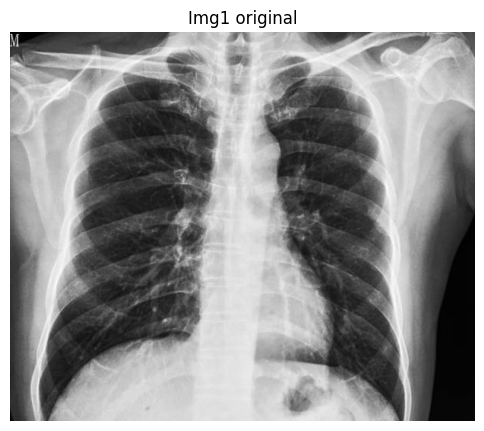

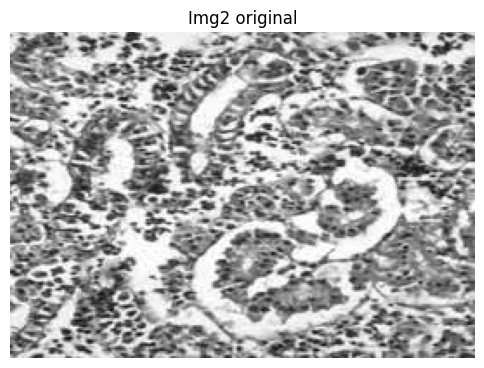

In [15]:
import matplotlib.pyplot as plt

if img1 is not None: show([img1],['Img1 original'],figsize=(6,6))
if img2 is not None: show([img2],['Img2 original'],figsize=(6,6))

In [16]:
def smoothing(img):
    u=(img*255).astype(np.uint8)
    sizes=[3,5,11]
    out={}
    for k in sizes:
        out[f'media_{k}']=cv2.blur(u,(k,k)).astype(np.float32)/255.0
        out[f'gauss_{k}']=cv2.GaussianBlur(u,(k,k),0).astype(np.float32)/255.0
        out[f'mediana_{k}']=cv2.medianBlur(u,k).astype(np.float32)/255.0
    return out

In [17]:
def edges(img):
    u=(img*255).astype(np.uint8)
    sx=cv2.Sobel(u,cv2.CV_64F,1,0,ksize=3); sy=cv2.Sobel(u,cv2.CV_64F,0,1,ksize=3)
    lap=np.abs(cv2.Laplacian(u,cv2.CV_64F))
    sobmag=np.hypot(sx,sy)
    # Kirsch: 8 máscaras direccionales
    K=[np.array([[5,5,5],[-3,0,-3],[-3,-3,-3]],np.float32),
        np.array([[5,5,-3],[5,0,-3],[-3,-3,-3]],np.float32),
        np.array([[5,-3,-3],[5,0,-3],[5,-3,-3]],np.float32),
        np.array([[-3,-3,-3],[5,0,-3],[5,5,-3]],np.float32),
        np.array([[-3,-3,-3],[-3,0,-3],[5,5,5]],np.float32),
        np.array([[-3,-3,-3],[-3,0,5],[-3,5,5]],np.float32),
        np.array([[-3,-3,5],[-3,0,5],[-3,-3,5]],np.float32),
        np.array([[-3,5,5],[-3,0,5],[-3,-3,-3]],np.float32)]
    kr=[cv2.filter2D(u.astype(np.float32),-1,k) for k in K]
    kir=np.max(np.stack(kr),axis=0)
    def norm(a): a=a-a.min(); return a/(a.max() if a.max()!=0 else 1)
    return {'sobelx':norm(np.abs(sx)),'sobely':norm(np.abs(sy)),'sobel_mag':norm(sobmag),'lap':norm(lap),'kirsch':norm(kir)}

In [18]:
def apply_kernel(img,kernel):
    u=(img*255).astype(np.uint8)
    r=cv2.filter2D(u.astype(np.float32),-1,kernel)
    r=r-r.min(); return r/(r.max() if r.max()!=0 else 1)

In [19]:

if img1 is not None:
    sm=smoothing(img1)

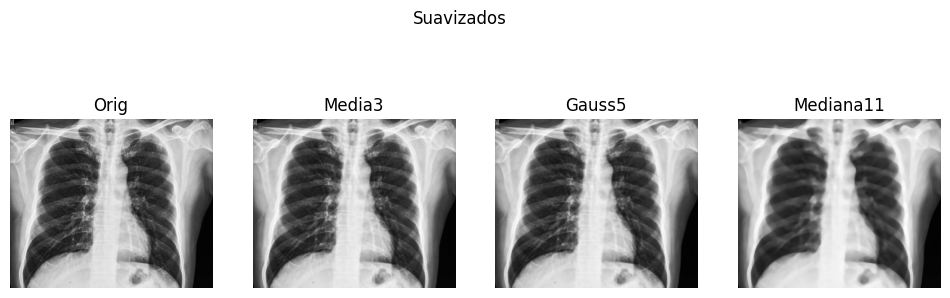

In [20]:
show([img1,sm['media_3'],sm['gauss_5'],sm['mediana_11']], ['Orig','Media3','Gauss5','Mediana11'], suptitle='Suavizados')
ed=edges(img1)

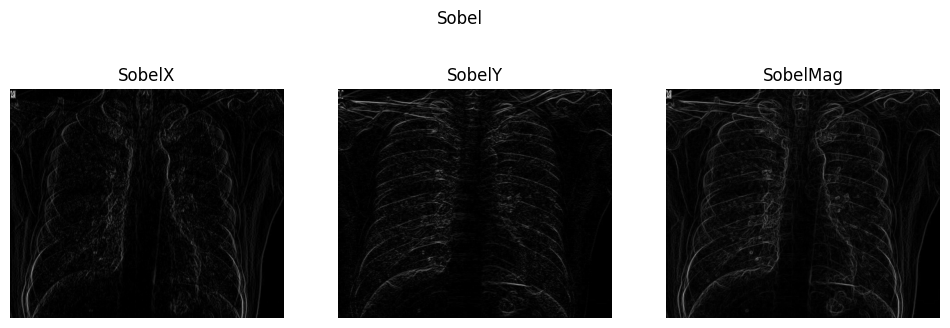

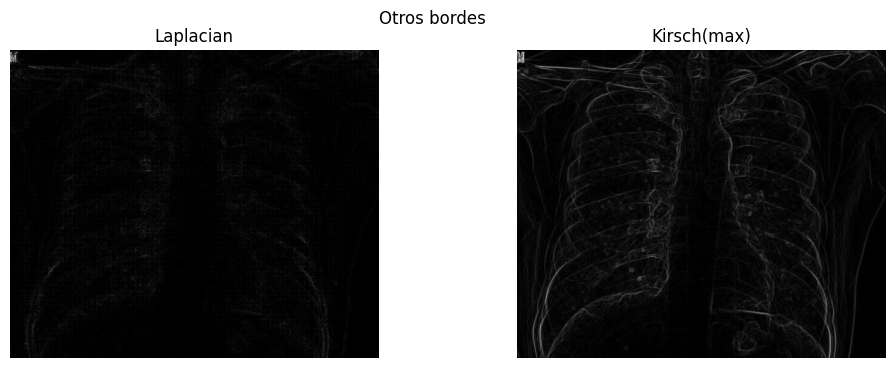

In [21]:

show([ed['sobelx'],ed['sobely'],ed['sobel_mag']],['SobelX','SobelY','SobelMag'], suptitle='Sobel')
show([ed['lap'],ed['kirsch']],['Laplacian','Kirsch(max)'], suptitle='Otros bordes')

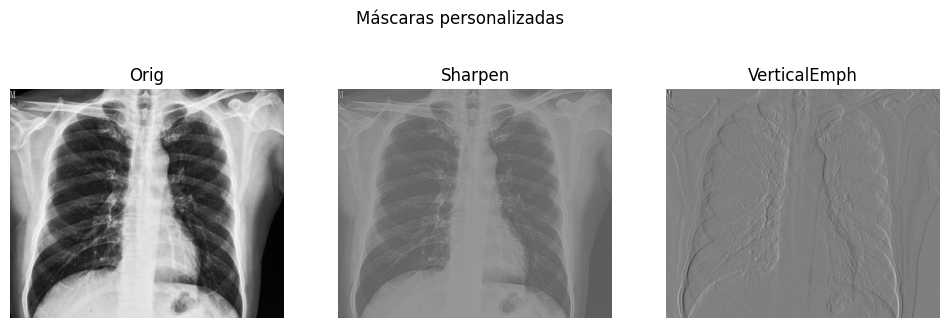

In [22]:
custom_sh=np.array([[0,-1,0],[-1,5,-1],[0,-1,0]],np.float32)
custom_vert=np.array([[-1,0,1],[-2,0,2],[-1,0,1]],np.float32)
show([img1,apply_kernel(img1,custom_sh),apply_kernel(img1,custom_vert)],['Orig','Sharpen','VerticalEmph'], suptitle='Máscaras personalizadas')

In [23]:
def fft(img):
    F=np.fft.fftshift(np.fft.fft2(img)); M=np.log1p(np.abs(F)); M=(M-M.min())/(M.max()-M.min() if M.max()!=M.min() else 1)
    return F,M
def ifft(Fshift):
    f=np.fft.ifft2(np.fft.ifftshift(Fshift)); r=np.real(f); r=r-r.min(); return r/(r.max() if r.max()!=0 else 1)

In [24]:
def circ_mask(shape,r):
    rows,cols=shape; cy, cx=rows//2, cols//2; Y,X=np.ogrid[:rows,:cols]; m=((Y-cy)**2+(X-cx)**2)<=r*r; return m.astype(np.float32)

def ring_mask(shape,ri,ro):
    rows,cols=shape; cy, cx=rows//2, cols//2; Y,X=np.ogrid[:rows,:cols]; d=np.sqrt((Y-cy)**2+(X-cx)**2); m=(d>=ri)&(d<=ro); return m.astype(np.float32)

def cross_mask(shape,th=5):
    rows,cols=shape; cy, cx=rows//2, cols//2; m=np.zeros(shape,np.float32); m[cy-th:cy+th+1,:]=1; m[:,cx-th:cx+th+1]=1; return m

In [25]:
def apply_freq(img,mask):
    F,M=fft(img); Fm=F*mask; imgb=ifft(Fm); Mm=np.log1p(np.abs(Fm)); Mm=(Mm-Mm.min())/(Mm.max()-Mm.min() if Mm.max()!=Mm.min() else 1)
    return imgb, M, Mm, mask

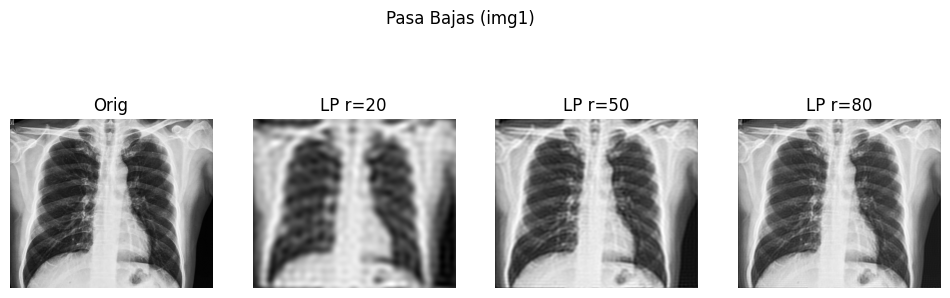

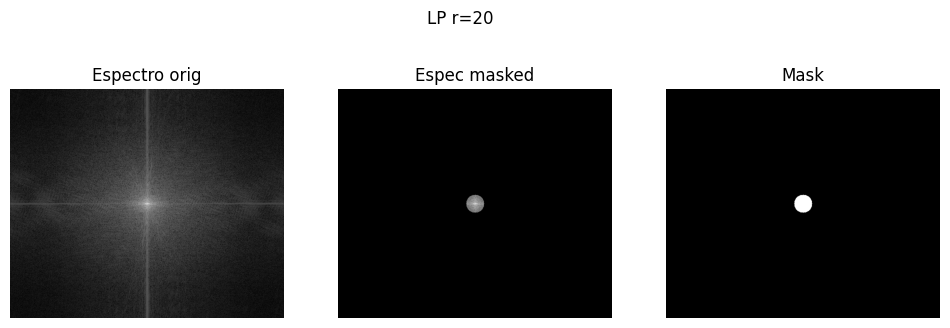

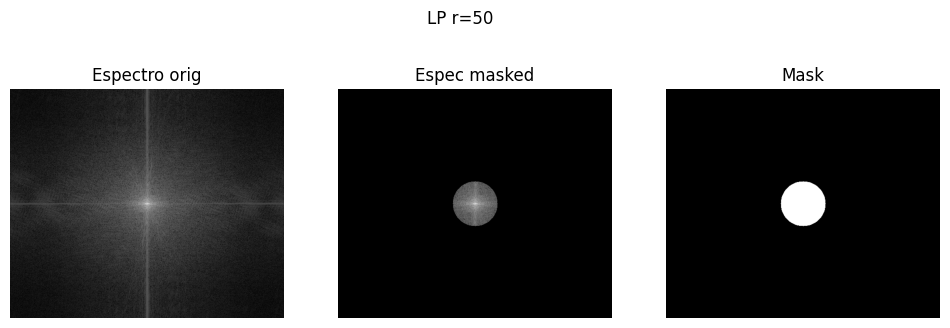

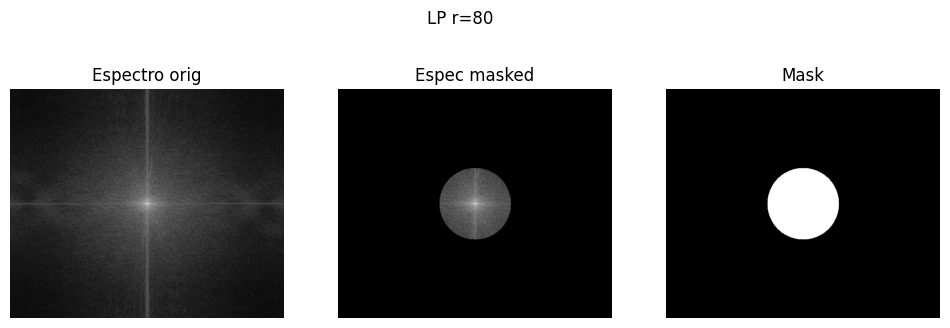

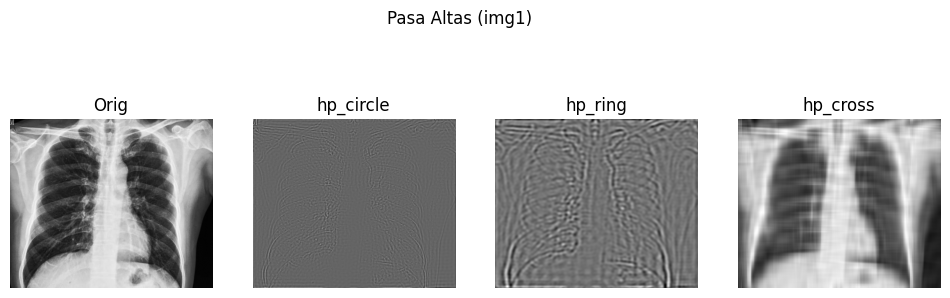

In [26]:
if img1 is not None:
    rows,cols=img1.shape; radios=[20,50,80]; radios=[min(max(3,r),min(rows,cols)//2-1) for r in radios]
    lp=[]
    for r in radios:
        imgb,M,Mm,mask=apply_freq(img1,circ_mask(img1.shape,r)); lp.append((r,imgb,M,Mm,mask))
    show([img1]+[x[1] for x in lp],['Orig']+[f'LP r={x[0]}' for x in lp], suptitle='Pasa Bajas (img1)')
    for r,imgb,M,Mm,mask in lp: show([M,Mm,mask],['Espectro orig','Espec masked','Mask'], suptitle=f'LP r={r}')
    hp_cfg={'hp_circle':1-circ_mask(img1.shape,radios[1]),'hp_ring':ring_mask(img1.shape,radios[0],radios[1]),'hp_cross':cross_mask(img1.shape,5)}
    hp_res={k:apply_freq(img1,v) for k,v in hp_cfg.items()}
    show([img1]+[hp_res[k][0] for k in hp_res],['Orig']+list(hp_res.keys()), suptitle='Pasa Altas (img1)')

Aplicando filtros en frecuencia a la segunda imagen


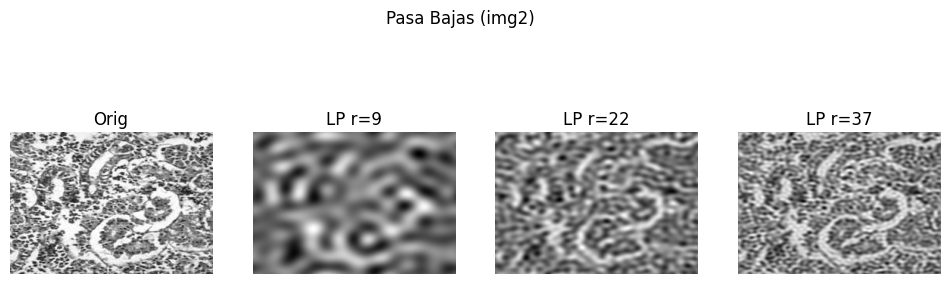

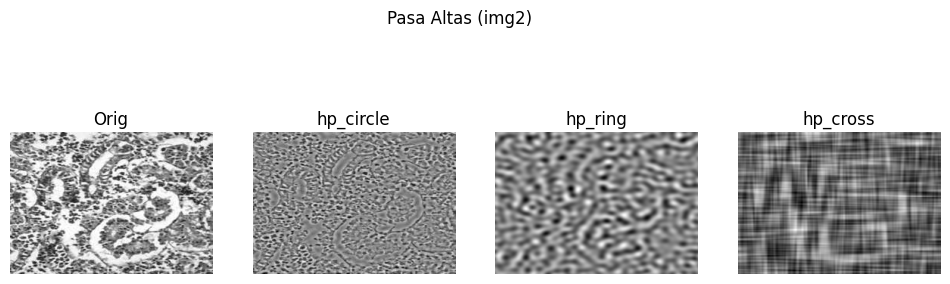

In [27]:
if img2 is not None:
    print('Aplicando filtros en frecuencia a la segunda imagen')
    rows2,cols2=img2.shape; radios2=[int(min(rows2,cols2)*0.05),int(min(rows2,cols2)*0.12),int(min(rows2,cols2)*0.2)]
    lp2=[]
    for r in radios2:
        imgb,M,Mm,mask=apply_freq(img2,circ_mask(img2.shape,r)); lp2.append((r,imgb,M,Mm,mask))
    show([img2]+[x[1] for x in lp2],['Orig']+[f'LP r={x[0]}' for x in lp2], suptitle='Pasa Bajas (img2)')
    hp2={'hp_circle':1-circ_mask(img2.shape,radios2[1]),'hp_ring':ring_mask(img2.shape,radios2[0],radios2[1]),'hp_cross':cross_mask(img2.shape,3)}
    hp2res={k:apply_freq(img2,v) for k,v in hp2.items()}
    show([img2]+[hp2res[k][0] for k in hp2res],['Orig']+list(hp2res.keys()), suptitle='Pasa Altas (img2)')

### 1. Suavizado Espacial (Filtros de Atenuación de Ruido)

**Explicación para el reporte:**
El suavizado espacial es una técnica de filtrado que busca reducir las variaciones de alta frecuencia (ruido, detalles finos) reemplazando cada píxel con un promedio ponderado o no ponderado de su vecindario. En este laboratorio implementamos tres variantes:
*   **Filtro de Media (Caja):** Reemplaza cada píxel con el promedio aritmético de sus vecinos. Es efectivo para ruido uniforme pero difumina excesivamente los bordes rectos.
*   **Filtro Gaussiano:** Utiliza un kernel con pesos basados en la distribución normal bidimensional. Preserva mejor las estructuras espaciales y la continuidad de los bordes que el filtro de media simple.
*   **Filtro de Mediana:** Es un filtro no lineal de orden estadístico. Excelente para eliminar ruido de tipo 'sal y pimienta' sin destruir la definición de los bordes nítidos de la imagen.

In [28]:
def aplicar_suavizados(matriz_imagen):
    # Convertimos a rango entero para la suite de OpenCV
    img_uint8 = (matriz_imagen * 255).astype(np.uint8)
    dimensiones_kernel = [3, 5, 11]
    resultados_suavizado = {}

    for tam in dimensiones_kernel:
        # Filtro de promedio espacial tradicional
        resultados_suavizado[f'media_local_{tam}'] = cv2.blur(img_uint8, (tam, tam)).astype(np.float32) / 255.0
        # Filtro gaussiano con desviación estándar calculada automáticamente
        resultados_suavizado[f'gaussiana_{tam}'] = cv2.GaussianBlur(img_uint8, (tam, tam), 0).astype(np.float32) / 255.0
        # Filtro no lineal de mediana
        resultados_suavizado[f'mediana_local_{tam}'] = cv2.medianBlur(img_uint8, tam).astype(np.float32) / 255.0

    return resultados_suavizado

### 2. Detección de Bordes y Gradientes (Operadores Diferenciales)

**Explicación para el reporte:**
Los bordes corresponden a transiciones rápidas en la intensidad luminosa de la imagen. Matemáticamente, se modelan mediante derivadas espaciales:
*   **Operador Sobel:** Aproxima la primera derivada parcial de la imagen en las direcciones horizontal ($X$) y vertical ($Y$). La magnitud del gradiente combina ambos componentes para resaltar los bordes sin importar su orientación.
*   **Laplaciano:** Es un operador diferencial isotrópico de segunda derivada. Es altamente sensible a cambios bruscos de gradiente y cruces por cero, aunque también es muy sensible al ruido de alta frecuencia.
*   **Filtro de Kirsch:** Es un método direccional basado en una brújula de 8 plantillas giradas a intervalos de 45°. Se obtiene la respuesta máxima de las 8 direcciones para resaltar las discontinuidades más dominantes en cualquier sentido geométrico.

In [29]:
def detectar_contornos_gradiente(matriz_imagen):
    u_img = (matriz_imagen * 255).astype(np.uint8)

    # Gradientes direccionales de Sobel
    grad_x = cv2.Sobel(u_img, cv2.CV_64F, 1, 0, ksize=3)
    grad_y = cv2.Sobel(u_img, cv2.CV_64F, 0, 1, ksize=3)

    # Magnitud euclidiana del gradiente
    magnitud_sobel = np.sqrt(grad_x**2 + grad_y**2)

    # Segunda derivada mediante operador Laplaciano
    laplaciano_img = np.abs(cv2.Laplacian(u_img, cv2.CV_64F))

    # Configuración de máscaras direccionales para el método de Kirsch
    mascaras_kirsch = [
        np.array([[ 5,  5,  5], [-3,  0, -3], [-3, -3, -3]], dtype=np.float32),
        np.array([[ 5,  5, -3], [ 5,  0, -3], [-3, -3, -3]], dtype=np.float32),
        np.array([[ 5, -3, -3], [ 5,  0, -3], [ 5, -3, -3]], dtype=np.float32),
        np.array([[-3, -3, -3], [ 5,  0, -3], [ 5,  5, -3]], dtype=np.float32),
        np.array([[-3, -3, -3], [-3,  0, -3], [ 5,  5,  5]], dtype=np.float32),
        np.array([[-3, -3, -3], [-3,  0,  5], [-3,  5,  5]], dtype=np.float32),
        np.array([[-3, -3,  5], [-3,  0,  5], [-3, -3,  5]], dtype=np.float32),
        np.array([[-3,  5,  5], [-3,  0,  5], [-3, -3, -3]], dtype=np.float32)
    ]

    # Aplicación y extracción del valor máximo absoluto de respuesta direccional
    filtrados_kirsch = [cv2.filter2D(u_img.astype(np.float32), -1, m) for m in mascaras_kirsch]
    respuesta_kirsch = np.max(np.stack(filtrados_kirsch), axis=0)

    # Función interna de normalización al intervalo lineal [0, 1]
    def escalar_rango(arreglo):
        min_v = arreglo.min()
        max_v = arreglo.max()
        rango = max_v - min_v
        return (arreglo - min_v) / (rango if rango != 0 else 1.0)

    return {
        'sobel_horizontal': escalar_rango(np.abs(grad_x)),
        'sobel_vertical': escalar_rango(np.abs(grad_y)),
        'sobel_magnitud': escalar_rango(magnitud_sobel),
        'laplaciano_abs': escalar_rango(laplaciano_img),
        'kirsch_final': escalar_rango(respuesta_kirsch)
    }

### 3. Filtrado Lineal en el Dominio de la Frecuencia (Transformada de Fourier)

**Explicación para el reporte:**
La Transformada de Fourier Bidimensional ($2D$-$FFT$) proyecta la información de la imagen espacial en coeficientes senoidales en función de frecuencias espaciales horizontales y verticales.
*   **Filtro Pasa Bajas (LPF):** Atenúa las frecuencias altas a una distancia radial del origen espectral mayor que una frecuencia de corte dada. Esto suaviza los bordes y el ruido de la imagen original.
*   **Filtro Pasa Altas (HPF):** Bloquea las frecuencias de fondo o de baja variación espacial (atenuando el brillo uniforme) y deja pasar los cambios bruscos de intensidad, logrando destacar las siluetas, el ruido de alta frecuencia y los bordes finos de los tejidos corporales (como en la radiografía) o la textura celular (en el corte histológico).

In [32]:
def procesar_frecuencia_bidimensional(matriz_imagen):
    # Transformada Rápida de Fourier en 2D con centrado espectral (frecuencias cero al centro)
    espectro_fourier = np.fft.fftshift(np.fft.fft2(matriz_imagen))

    # Magnitud logarítmica para visualización del espectro de potencias
    magnitud_espectral = np.log1p(np.abs(espectro_fourier))
    min_m = magnitud_espectral.min()
    max_m = magnitud_espectral.max()
    magnitud_espectral_norm = (magnitud_espectral - min_m) / (max_m - min_m if max_m != min_m else 1.0)

    return espectro_fourier, magnitud_espectral_norm

def reconstruir_desde_frecuencia(espectro_fourier_filtrado):
    # Transformada inversa regresando el espectro al origen y aplicando IFFT
    matriz_espacial = np.fft.ifft2(np.fft.ifftshift(espectro_fourier_filtrado))
    # Extracción de la componente real útil
    componente_real = np.real(matriz_espacial)
    min_r, max_r = componente_real.min(), componente_real.max()
    return (componente_real - min_r) / (max_r - min_r if max_r != 0 else 1.0)

def aplicar_mascara_frecuencia(matriz_imagen, mascara_espectral):
    # Flujo completo: transformación, modulación espectral por la máscara, y reconstrucción
    f_shift, m_original = procesar_frecuencia_bidimensional(matriz_imagen)
    f_filtrada = f_shift * mascara_espectral
    imagen_reconstruida = reconstruir_desde_frecuencia(f_filtrada)

    # Magnitud del espectro modulado
    m_modulada = np.log1p(np.abs(f_filtrada))
    min_mm, max_mm = m_modulada.min(), m_modulada.max()
    m_modulada_norm = (m_modulada - min_mm) / (max_mm - min_mm if max_mm != min_mm else 1.0)

    return imagen_reconstruida, m_original, m_modulada_norm, mascara_espectral

### 4. Demostración y Ejecución de los Nuevos Algoritmos

Ejecutamos las nuevas implementaciones sobre las imágenes del espacio de trabajo para corroborar que el procesamiento genera los resultados esperados para nuestro reporte de laboratorio.

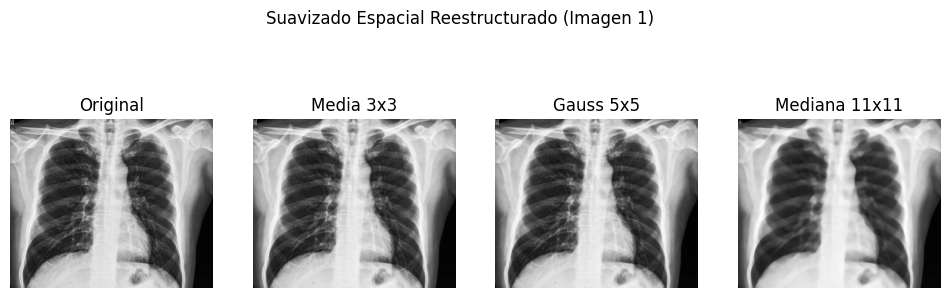

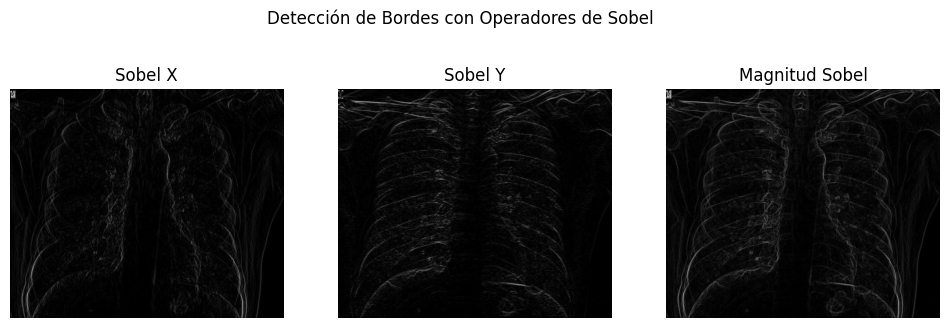

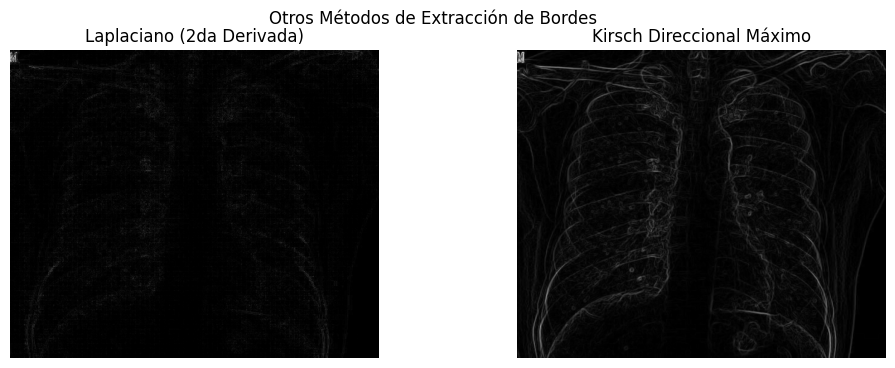

In [31]:
if img1 is not None:
    # 1. Ejecutar suavizados
    suavizados_nuevos = aplicar_suavizados(img1)
    show([img1, suavizados_nuevos['media_local_3'], suavizados_nuevos['gaussiana_5'], suavizados_nuevos['mediana_local_11']],
         ['Original', 'Media 3x3', 'Gauss 5x5', 'Mediana 11x11'],
         suptitle='Suavizado Espacial Reestructurado (Imagen 1)')

    # 2. Ejecutar detección de bordes
    bordes_nuevos = detectar_contornos_gradiente(img1)
    show([bordes_nuevos['sobel_horizontal'], bordes_nuevos['sobel_vertical'], bordes_nuevos['sobel_magnitud']],
         ['Sobel X', 'Sobel Y', 'Magnitud Sobel'],
         suptitle='Detección de Bordes con Operadores de Sobel')
    show([bordes_nuevos['laplaciano_abs'], bordes_nuevos['kirsch_final']],
         ['Laplaciano (2da Derivada)', 'Kirsch Direccional Máximo'],
         suptitle='Otros Métodos de Extracción de Bordes')